<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/gauge_theory/gauge_ch06_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Gauge Theory* — `gauge_ch06_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Gauge Theory Ch 6 Figures — Colab Notebook
**Gauge Theory · Chapter 6: Large N**

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §6.2.1 | Planar vs non-planar diagrams, $N^{2-2h}$ genus hierarchy |
| fig02  | §6.2.4 | Glueball decay topology, width $\sim1/N^2$ vs $N$, $\theta$-vacuum |
| fig03  | §6.3   | Width scaling, $f_\pi^2\sim N$, baryon mass $M_B\sim N$ |
| fig04  | §6.4.3 | Witten-Veneziano formula, $\chi_{\rm YM}^{1/4}$ vs $N$, $\eta'$ decomposition |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Circle, FancyBboxPatch
import os, warnings
warnings.filterwarnings('ignore')

BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
AMBER  = '#e8a838'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': AMBER, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

OUTDIR = 'figures/ch06'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete.')


Setup complete.


---
## fig01 · Planar vs Non-Planar Diagrams (§6.2.1)

**Left**: Planar diagram (sphere, $h=0$) — dominant at large $N$, each colour loop → factor $N$  
**Middle**: Non-planar diagram (torus, $h=1$) — suppressed by $1/N^2$  
**Right**: $N^{2-2h}$ hierarchy identifies the $1/N$ expansion with a string theory ($g_s=1/N$)

  saved -> figures/ch06/fig01_planar.png


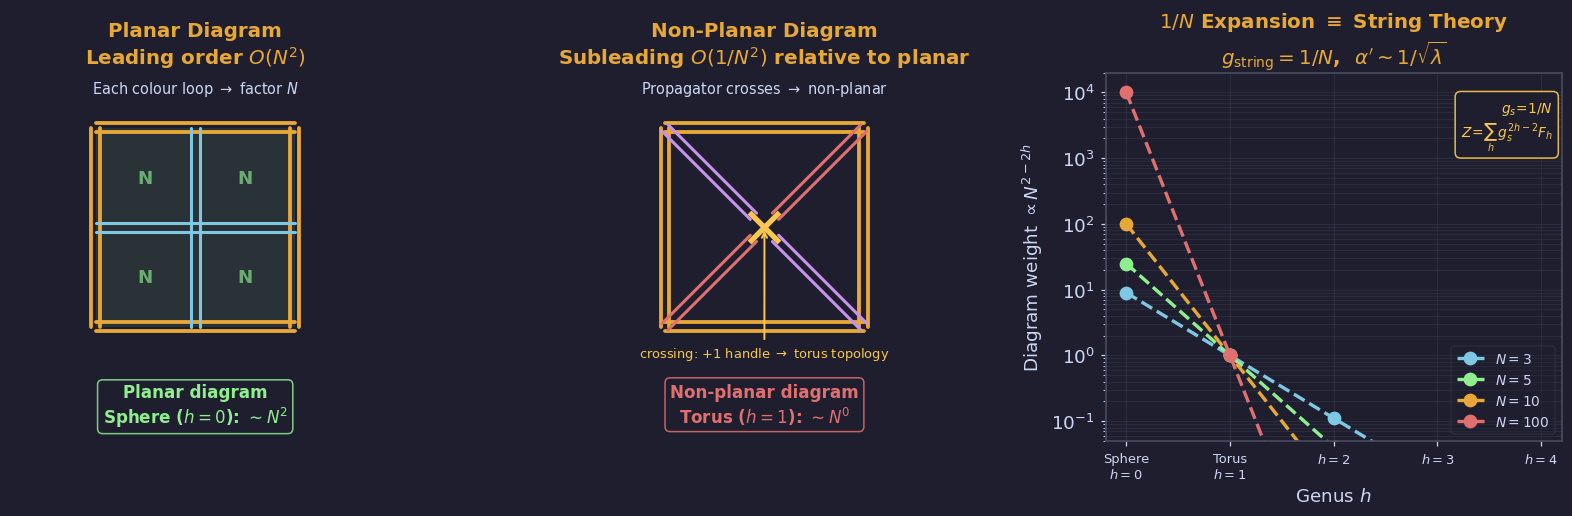

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

def dbl(ax, x1, y1, x2, y2, col, lw=2.2, gap=0.012):
    dx, dy = x2 - x1, y2 - y1
    L = np.hypot(dx, dy) + 1e-9
    nx, ny = -dy / L * gap, dx / L * gap
    kw = dict(color=col, lw=lw, solid_capstyle='round')
    ax.plot([x1+nx, x2+nx], [y1+ny, y2+ny], **kw)
    ax.plot([x1-nx, x2-nx], [y1-ny, y2-ny], **kw)

s = 0.27; cx, cy = 0.50, 0.58
corners = [(cx-s, cy-s), (cx+s, cy-s), (cx+s, cy+s), (cx-s, cy+s)]

# ── Left: Planar diagram ──────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_aspect('equal'); ax.axis('off')

for k in range(4):
    x1, y1 = corners[k]; x2, y2 = corners[(k+1) % 4]
    dbl(ax, x1, y1, x2, y2, AMBER, lw=2.5)
dbl(ax, cx-s, cy, cx+s, cy, BLUE, lw=2.0)
dbl(ax, cx, cy-s, cx, cy+s, BLUE, lw=2.0)

for rx, ry in [(cx-s, cy), (cx, cy), (cx-s, cy-s), (cx, cy-s)]:
    ax.add_patch(plt.Polygon([(rx, ry), (rx+s, ry), (rx+s, ry+s), (rx, ry+s)],
                 closed=True, fc=GREEN, alpha=0.10, ec='none'))
for lx, ly in [(cx-s/2, cy+s/2), (cx+s/2, cy+s/2),
                (cx-s/2, cy-s/2), (cx+s/2, cy-s/2)]:
    ax.text(lx, ly, 'N', ha='center', va='center',
            fontsize=12, color=GREEN, alpha=0.65, fontweight='bold')

ax.text(cx, 0.05, 'Planar diagram\n' + r'Sphere ($h=0$): $\sim N^2$',
        ha='center', fontsize=11, color=GREEN, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=GREEN, alpha=0.85))
ax.text(cx, 0.945, r'Each colour loop $\to$ factor $N$',
        ha='center', fontsize=9.5, color=FG)
ax.set_title('Planar Diagram\n' + r'Leading order $O(N^2)$')

# ── Middle: Non-planar diagram ────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.set_xlim(0, 1); ax2.set_ylim(0, 1)
ax2.set_aspect('equal'); ax2.axis('off')

for k in range(4):
    x1, y1 = corners[k]; x2, y2 = corners[(k+1) % 4]
    dbl(ax2, x1, y1, x2, y2, AMBER, lw=2.5)

for xa, ya, xb, yb, col in [
    (cx-s, cy-s, cx-0.03, cy-0.03, RED),
    (cx+0.03, cy+0.03, cx+s, cy+s, RED),
    (cx+s, cy-s, cx+0.03, cy-0.03, PURPLE),
    (cx-0.03, cy+0.03, cx-s, cy+s, PURPLE),
]:
    dbl(ax2, xa, ya, xb, yb, col, lw=2.0)

ax2.plot(cx, cy, 'x', color=YELLOW, ms=20, mew=3.5, zorder=5)

# Arrow from crossing X to annotation — no floating oval
ax2.annotate(r'crossing: $+1$ handle $\to$ torus topology',
             xy=(cx, cy), xytext=(cx - 0.34, cy - 0.32),
             fontsize=8.5, color=YELLOW, va='top',
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.3))

ax2.text(cx, 0.945, r'Propagator crosses $\to$ non-planar',
         ha='center', fontsize=9.5, color=FG)
ax2.text(cx, 0.05, 'Non-planar diagram\n' + r'Torus ($h=1$): $\sim N^0$',
         ha='center', fontsize=11, color=RED, fontweight='bold',
         bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=RED, alpha=0.85))
ax2.set_title('Non-Planar Diagram\n' + r'Subleading $O(1/N^2)$ relative to planar')

# ── Right: N^{2-2h} genus hierarchy ──────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

h_vals = np.arange(0, 5)
for N_v, col in zip([3, 5, 10, 100], [BLUE, GREEN, AMBER, RED]):
    ax3.semilogy(h_vals, N_v**(2 - 2*h_vals.astype(float)),
                 'o--', color=col, lw=2.2, ms=8, label=f'$N={N_v}$')

# Genus labels as x-tick labels — always visible, no overlap with data
ax3.set_xticks(h_vals)
ax3.set_xticklabels([r'Sphere' + '\n' + r'$h=0$', r'Torus' + '\n' + r'$h=1$',
                      r'$h=2$', r'$h=3$', r'$h=4$'], fontsize=8.5, color=FG)

# Formula box: axes fraction coords + right-aligned — always inside
ax3.text(0.98, 0.97,
         '\n' + r'$g_s\!=\!1/N$' + '\n' + r'$Z\!=\!\sum_h\,g_s^{2h-2}F_h$',
         fontsize=9.0, color=YELLOW, ha='right', va='top',
         transform=ax3.transAxes,
         bbox=dict(boxstyle='round,pad=0.4', fc=BG, ec=YELLOW, alpha=0.92),
         clip_on=False)

ax3.set_xlabel('Genus $h$')
ax3.set_ylabel(r'Diagram weight $\propto N^{2-2h}$')
ax3.set_title(r'$1/N$ Expansion $\equiv$ String Theory' + '\n' +
              r'$g_{\rm string}=1/N$,  $\alpha^{\prime}\sim 1/\sqrt{\lambda}$')
ax3.legend(fontsize=9, labelcolor=FG)
ax3.set_ylim(0.05, 2e4)
ax3.grid(True, which='both', alpha=0.3)

plt.tight_layout(pad=1.5)
save('fig01_planar.png', fig)

---
## fig02 · Glueball Decay (§6.2.4)

**Left**: Glueball 2-point (disk, $O(N^2)$) vs 3-point (handle, $O(N^0)$) topology  
**Middle**: Glueball decay width $\Gamma\sim 1/N^2$ and meson $\Gamma\sim 1/N$ vs $N$  
**Right**: $\theta$-vacuum energy $E(\theta)=N^2 f(\theta/N)$ — cusp (1st-order transition) at $\theta=\pi$

  saved -> figures/ch06/fig02_glueball.png


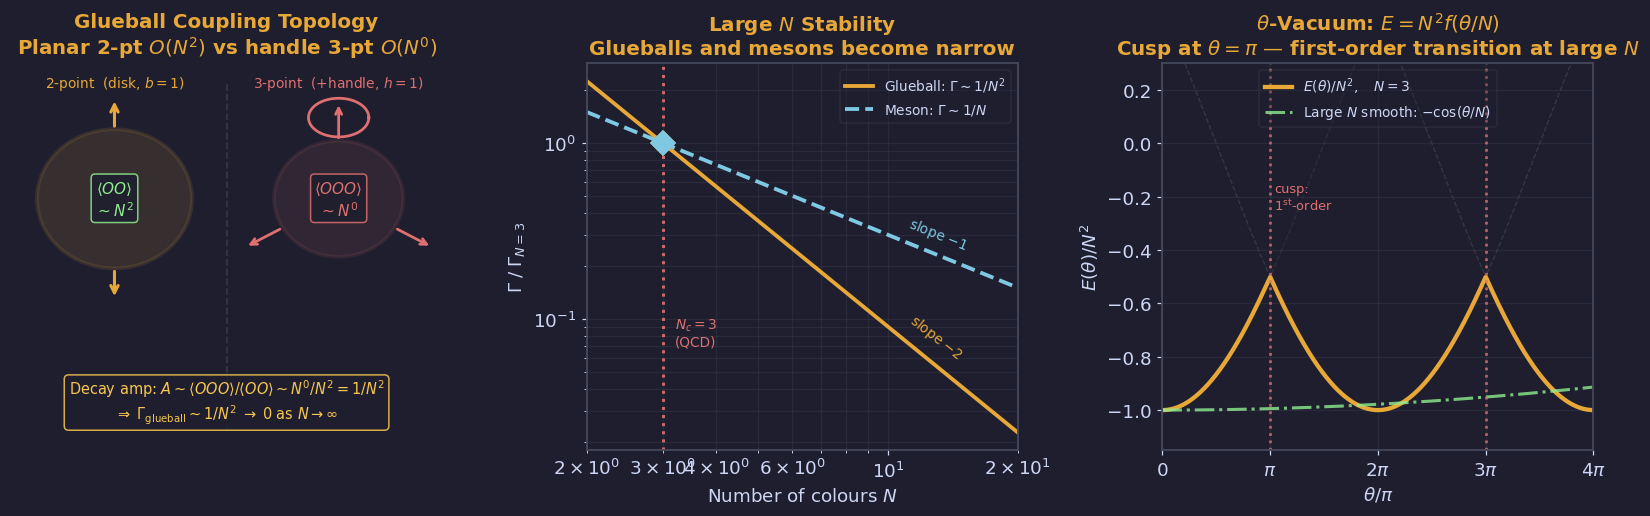

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: 2-point (disk) vs 3-point (handle) glueball topology ──────
ax = axes[0]
ax.set_facecolor(BG); ax.axis('off')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

# --- 2-point: disk topology → O(N^2) ---
c2 = Circle((0.24, 0.65), 0.18, fc=AMBER, alpha=0.12, ec=AMBER, lw=2.5)
ax.add_patch(c2)
for dy_a, dy_b in [(0.18, 0.26), (-0.18, -0.26)]:
    ax.annotate('', xy=(0.24, 0.65+dy_b), xytext=(0.24, 0.65+dy_a),
                arrowprops=dict(arrowstyle='->', color=AMBER, lw=2, mutation_scale=12),
                xycoords='axes fraction', textcoords='axes fraction')
ax.text(0.24, 0.65, r'$\langle OO\rangle$' + '\n' + r'$\sim N^2$',
        ha='center', va='center', fontsize=10, color=GREEN, fontweight='bold',
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=GREEN, alpha=0.85))

# Divider
ax.axvline(0.50, ymin=0.05, ymax=0.95, color=EDGE, lw=1.2, ls='--', alpha=0.55)

# --- 3-point: handle topology → O(N^0) ---
c3 = Circle((0.76, 0.65), 0.15, fc=RED, alpha=0.10, ec=RED, lw=2.5)
ax.add_patch(c3)
# Handle (small loop = extra handle on the Riemann surface)
th = np.linspace(0, 2*np.pi, 80)
ax.plot(0.76 + 0.07*np.cos(th), 0.65 + 0.15 + 0.06 + 0.05*np.sin(th),
        color=RED, lw=1.8, transform=ax.transAxes)
# 3 external legs
for angle in [210, 330, 90]:
    r = np.radians(angle)
    ax.annotate('', xy=(0.76+0.25*np.cos(r), 0.65+0.25*np.sin(r)),
                xytext=(0.76+0.15*np.cos(r), 0.65+0.15*np.sin(r)),
                arrowprops=dict(arrowstyle='->', color=RED, lw=1.8, mutation_scale=10),
                xycoords='axes fraction', textcoords='axes fraction')
ax.text(0.76, 0.65, r'$\langle OOO\rangle$' + '\n' + r'$\sim N^0$',
        ha='center', va='center', fontsize=10, color=RED, fontweight='bold',
        transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=RED, alpha=0.85))

# Bottom: decay amplitude formula
ax.text(0.50, 0.08,
        r'Decay amp: $A\sim\langle OOO\rangle/\langle OO\rangle\sim N^0/N^2=1/N^2$'
        + '\n' + r'$\Rightarrow\;\Gamma_{\rm glueball}\sim 1/N^2\;\to\;0$ as $N\to\infty$',
        ha='center', fontsize=9.5, color=YELLOW, transform=ax.transAxes,
        bbox=dict(boxstyle='round,pad=0.3', fc=BG, ec=YELLOW, alpha=0.85))
ax.text(0.24, 0.94, '2-point  (disk, $b=1$)', ha='center', fontsize=9,
        color=AMBER, transform=ax.transAxes)
ax.text(0.76, 0.94, '3-point  (+handle, $h=1$)', ha='center', fontsize=9,
        color=RED, transform=ax.transAxes)
ax.set_title('Glueball Coupling Topology\n' +
             r'Planar 2-pt $O(N^2)$ vs handle 3-pt $O(N^0)$')

# ── Middle: Decay width vs N (log-log) ───────────────────────────────
ax2 = axes[1]; ax2.set_facecolor(BG)

N_cont = np.linspace(2, 20, 300)
# Normalised so that both = 1 at N=3
ax2.loglog(N_cont, (3/N_cont)**2, color=AMBER, lw=2.5,
           label=r'Glueball: $\Gamma\sim 1/N^2$')
ax2.loglog(N_cont, (3/N_cont)**1, color=BLUE,  lw=2.5, ls='--',
           label=r'Meson: $\Gamma\sim 1/N$')

ax2.axvline(3, color=RED, lw=2, ls=':', alpha=0.9)
ax2.plot(3, 1.0, 'D', color=AMBER, ms=11, zorder=5)
ax2.plot(3, 1.0, 'D', color=BLUE,  ms=11, zorder=5)
ax2.text(3.2, 0.07, '$N_c=3$\n(QCD)', fontsize=9, color=RED)

# Slope labels
ax2.text(11, 0.25, r'slope $-1$', fontsize=9, color=BLUE, rotation=-22)
ax2.text(11, 0.06, r'slope $-2$', fontsize=9, color=AMBER, rotation=-38)

ax2.set_xlabel(r'Number of colours $N$')
ax2.set_ylabel(r'$\Gamma\;/\;\Gamma_{N=3}$')
ax2.set_title(r'Large $N$ Stability' + '\nGlueballs and mesons become narrow')
ax2.legend(fontsize=9, labelcolor=FG)
ax2.set_xlim(2, 20); ax2.grid(True, which='both', alpha=0.3)

# ── Right: theta-vacuum energy, multi-branch with cusp at theta=pi ──
ax3 = axes[2]; ax3.set_facecolor(BG)

theta = np.linspace(0, 4*np.pi, 1200)
N_plot = 3

# E(theta)/N^2 = min_k [ -cos((theta - 2pi k)/N) ]
E_min = np.full_like(theta, np.inf)
for k in range(-5, 6):
    np.minimum(E_min, -np.cos((theta - 2*np.pi*k)/N_plot), out=E_min)

# Individual branches (faint)
for k in range(-2, 3):
    ax3.plot(theta/np.pi, -np.cos((theta - 2*np.pi*k)/N_plot),
             color=EDGE, lw=0.9, ls='--', alpha=0.35)

ax3.plot(theta/np.pi, E_min, color=AMBER, lw=2.8,
         label=r'$E(\theta)/N^2,\quad N=3$')

# Large-N smooth envelope: -cos(theta/N) ~ -1 + theta^2/(2N^2)
N_lg = 30
ax3.plot(theta/np.pi, -np.cos(theta/N_lg), color=GREEN, lw=2, ls='-.',
         alpha=0.8, label=r'Large $N$ smooth: $-\cos(\theta/N)$')

# Cusp markers at theta = pi, 3pi
for tc in [1, 3]:
    ax3.axvline(tc, color=RED, lw=1.8, ls=':', alpha=0.8)
ax3.text(1.04, -0.25, r'cusp:' + '\n' + r'$1^{\rm st}$-order', fontsize=8.5, color=RED)

ax3.set_xlabel(r'$\theta/\pi$')
ax3.set_ylabel(r'$E(\theta)/N^2$')
ax3.set_title(r'$\theta$-Vacuum: $E=N^2 f(\theta/N)$' + '\n' +
              r'Cusp at $\theta=\pi$ — first-order transition at large $N$')
ax3.set_xticks([0, 1, 2, 3, 4])
ax3.set_xticklabels(['$0$', r'$\pi$', r'$2\pi$', r'$3\pi$', r'$4\pi$'])
ax3.set_xlim(0, 4); ax3.set_ylim(-1.15, 0.30)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, alpha=0.3)

plt.tight_layout(pad=1.5)
save('fig02_glueball.png', fig)


---
## fig03 · Large N QCD Scaling (§6.3)

**Left**: Log-log width scaling — meson $\sim 1/N$, glueball $\sim 1/N^2$  
**Middle**: $f_\pi^2\sim N$ from lattice-like data  
**Right**: Baryon mass $M_B\sim N$ — quark model and Skyrmion give the same linear scaling

  saved -> figures/ch06/fig03_n_scaling.png


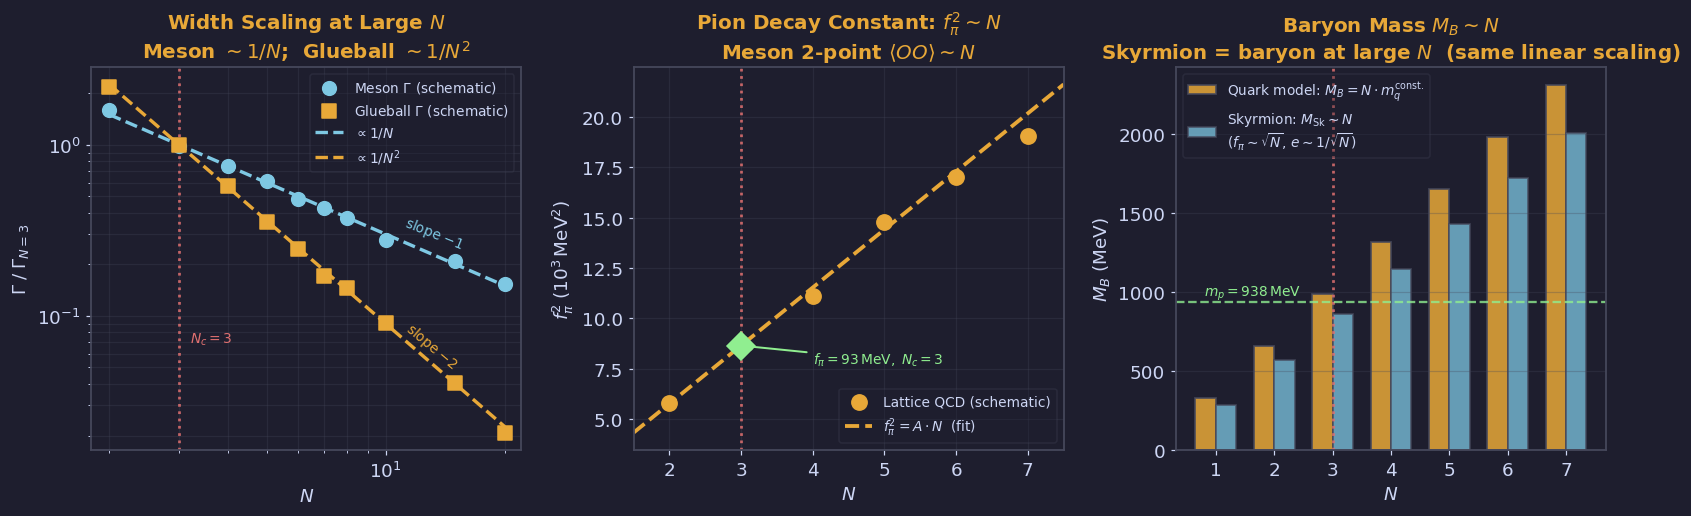

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: Width scaling log-log ───────────────────────────────────────
ax = axes[0]; ax.set_facecolor(BG)

N_disc = np.array([2, 3, 4, 5, 6, 7, 8, 10, 15, 20], dtype=float)
N_cont = np.linspace(2, 20, 300)
np.random.seed(7)
Gm = (3/N_disc) * (1 + np.random.normal(0, 0.04, len(N_disc)))
Gg = (3/N_disc)**2 * (1 + np.random.normal(0, 0.05, len(N_disc)))

ax.scatter(N_disc, Gm, color=BLUE,  s=80, zorder=5,
           label=r'Meson $\Gamma$ (schematic)')
ax.scatter(N_disc, Gg, color=AMBER, s=80, marker='s', zorder=5,
           label=r'Glueball $\Gamma$ (schematic)')
ax.loglog(N_cont, 3/N_cont,      color=BLUE,  lw=2.2, ls='--', label=r'$\propto 1/N$')
ax.loglog(N_cont, (3/N_cont)**2, color=AMBER, lw=2.2, ls='--', label=r'$\propto 1/N^2$')

ax.axvline(3, color=RED, lw=1.8, ls=':', alpha=0.85)
ax.text(3.2, 0.07, '$N_c=3$', fontsize=9, color=RED)
ax.text(11, 0.25, r'slope $-1$', fontsize=9, color=BLUE, rotation=-22)
ax.text(11, 0.05, r'slope $-2$', fontsize=9, color=AMBER, rotation=-40)

ax.set_xlabel(r'$N$')
ax.set_ylabel(r'$\Gamma\;/\;\Gamma_{N=3}$')
ax.set_title(r'Width Scaling at Large $N$' + '\n' +
             r'Meson $\sim 1/N$;  Glueball $\sim 1/N^2$')
ax.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax.set_xlim(1.8, 22); ax.grid(True, which='both', alpha=0.3)

# ── Middle: f_pi^2 ~ N ────────────────────────────────────────────────
ax2 = axes[1]; ax2.set_facecolor(BG)

N_lat = np.array([2, 3, 4, 5, 6, 7], dtype=float)
A = 93.0**2 / 3.0          # MeV^2 — so f_pi^2(N=3) = 93^2 MeV^2
fpi2_th = A * N_lat
np.random.seed(4)
fpi2_data = fpi2_th * (1 + np.random.normal(0, 0.035, len(N_lat)))

ax2.scatter(N_lat, fpi2_data/1e3, color=AMBER, s=100, zorder=5,
            label='Lattice QCD (schematic)')
N_fit = np.linspace(1.5, 7.5, 100)
ax2.plot(N_fit, A*N_fit/1e3, color=AMBER, lw=2.5, ls='--',
         label=r'$f_\pi^2 = A\cdot N$  (fit)')

ax2.axvline(3, color=RED, lw=1.8, ls=':', alpha=0.85)
ax2.plot(3, A*3/1e3, 'D', color=GREEN, ms=13, zorder=6)
ax2.annotate(r'$f_\pi=93\,\mathrm{MeV},\;N_c=3$',
             xy=(3, A*3/1e3), xytext=(4.0, A*3/1e3 - 0.9),
             fontsize=9, color=GREEN,
             arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.3))

ax2.set_xlabel(r'$N$')
ax2.set_ylabel(r'$f_\pi^2\;(10^3\,\mathrm{MeV}^2)$')
ax2.set_title(r'Pion Decay Constant: $f_\pi^2\sim N$' + '\n' +
              r'Meson 2-point $\langle OO\rangle\sim N$')
ax2.legend(fontsize=9, labelcolor=FG)
ax2.set_xlim(1.5, 7.5); ax2.grid(True, alpha=0.3)

# ── Right: Baryon mass M_B ~ N  (Skyrmion: correct N scaling) ────────
ax3 = axes[2]; ax3.set_facecolor(BG)

N_B = np.arange(1, 8, dtype=float)

# Large-N quark-model: M_B = N * m_constituent
m_q_const = 330.0            # MeV constituent quark mass
M_B_qm = m_q_const * N_B

# Skyrmion: M_Sk = C * f_pi / e
#   f_pi ~ sqrt(N),  e ~ 1/sqrt(N)  (from large-N Lagrangian counting)
#   => M_Sk ~ N   (SAME linear scaling as quark model)
# Calibrate: M_Sk(N=3) = 860 MeV
M_Sk = (860.0 / 3.0) * N_B

w = 0.35
ax3.bar(N_B - w/2, M_B_qm, width=w, color=AMBER, alpha=0.85,
        edgecolor=EDGE, lw=1.2,
        label=r'Quark model: $M_B = N\cdot m_q^{\rm const.}$')
ax3.bar(N_B + w/2, M_Sk,   width=w, color=BLUE,  alpha=0.75,
        edgecolor=EDGE, lw=1.2,
        label=r'Skyrmion: $M_{\rm Sk}\sim N$' + '\n' +
              r'($f_\pi\sim\sqrt{N}$, $e\sim 1/\sqrt{N}$)')

ax3.axvline(3, color=RED,   lw=1.8, ls=':', alpha=0.85)
ax3.axhline(938, color=GREEN, lw=1.5, ls='--', alpha=0.80)
ax3.text(0.8, 980, r'$m_p=938\,\mathrm{MeV}$', fontsize=9, color=GREEN)

ax3.set_xlabel(r'$N$')
ax3.set_ylabel(r'$M_B\;(\mathrm{MeV})$')
ax3.set_title(r'Baryon Mass $M_B\sim N$' + '\n' +
              r'Skyrmion = baryon at large $N$  (same linear scaling)')
ax3.set_xticks(N_B.astype(int))
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True, axis='y', alpha=0.3)

plt.tight_layout(pad=1.5)
save('fig03_n_scaling.png', fig)


---
## fig04 · Witten-Veneziano Formula (§6.4.3)

**Left**: $m_{\eta'}$ vs $\chi_{\rm YM}^{1/4}$ — WV prediction and lattice point  
**Middle**: Topological susceptibility $\chi_{\rm YM}=O(N^0)$ from lattice  
**Right**: $\eta'$ mass decomposition: GOR (quark mass) + WV anomaly contribution

  saved -> figures/ch06/fig04_witten_veneziano.png


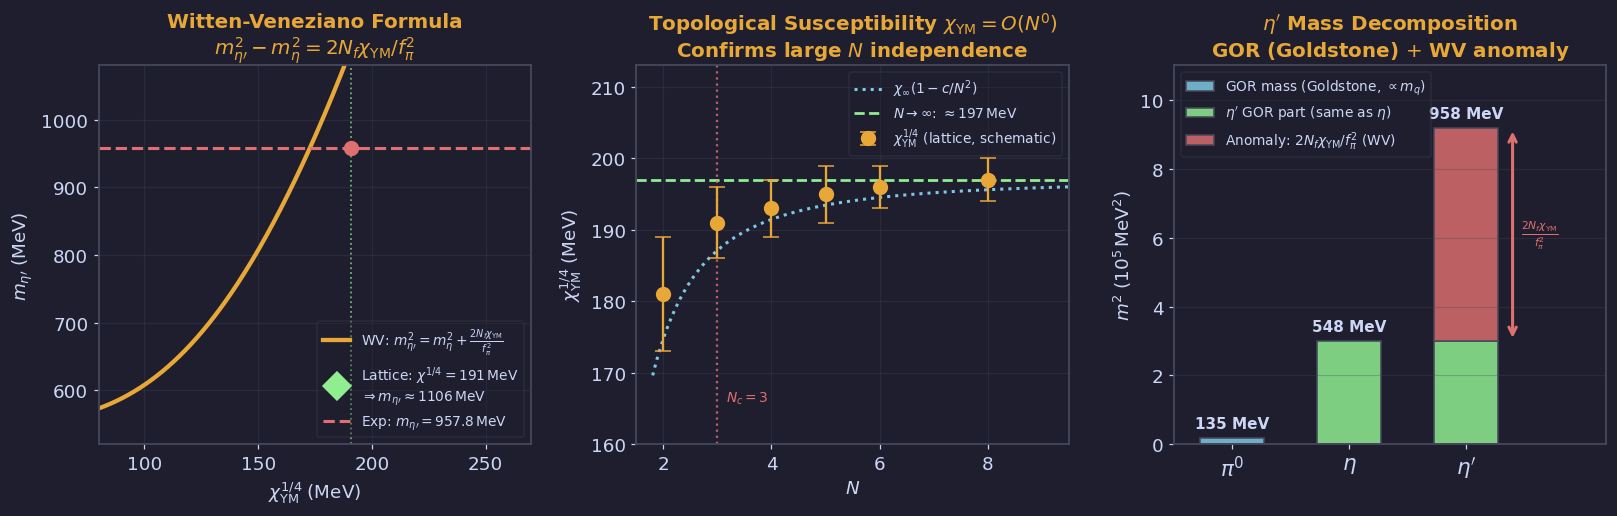

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

Nf       = 3
f_pi     = 93.0     # MeV
m_eta    = 547.86   # MeV  (physical eta)
m_etap_exp = 957.78  # MeV  (physical eta')

# ── Left: m_{eta'}  vs  chi_YM^{1/4}  (WV line) ─────────────────────
ax = axes[0]; ax.set_facecolor(BG)

# x-axis: chi_YM^{1/4} in MeV  (more physical than chi/f_pi^2)
chi14 = np.linspace(80, 270, 300)       # MeV
chi   = chi14**4                         # MeV^4
# WV: m_{eta'}^2 = m_eta^2 + (2*Nf/f_pi^2) * chi_YM
m_etap = np.sqrt(m_eta**2 + 2*Nf*chi/f_pi**2)

ax.plot(chi14, m_etap, color=AMBER, lw=2.8,
        label=r'WV: $m_{\eta\prime}^2=m_\eta^2+\frac{2N_f\chi_{\rm YM}}{f_\pi^2}$')

# Physical lattice point: chi^{1/4} = 191 MeV
chi14_lat = 191.0
chi_lat   = chi14_lat**4
m_etap_pred = np.sqrt(m_eta**2 + 2*Nf*chi_lat/f_pi**2)
ax.plot(chi14_lat, m_etap_pred, 'D', color=GREEN, ms=13, zorder=5,
        label=fr'Lattice: $\chi^{{1/4}}=191\,\mathrm{{MeV}}$'
              + '\n' + fr'$\Rightarrow m_{{\eta\prime}}\approx{m_etap_pred:.0f}\,\mathrm{{MeV}}$')
ax.axhline(m_etap_exp, color=RED, lw=2, ls='--',
           label=fr'Exp: $m_{{\eta\prime}}={m_etap_exp:.1f}\,\mathrm{{MeV}}$')
ax.axvline(chi14_lat, color=GREEN, lw=1.2, ls=':', alpha=0.7)
ax.plot(chi14_lat, m_etap_exp, 'o', color=RED, ms=9, zorder=4)

ax.set_xlabel(r'$\chi_{\rm YM}^{1/4}\;(\mathrm{MeV})$')
ax.set_ylabel(r'$m_{\eta\prime}\;(\mathrm{MeV})$')
ax.set_title('Witten-Veneziano Formula\n' +
             r'$m_{\eta\prime}^2 - m_\eta^2 = 2N_f\chi_{\rm YM}/f_\pi^2$')
ax.legend(fontsize=9, labelcolor=FG)
ax.set_xlim(80, 270); ax.set_ylim(520, 1080)
ax.grid(True, alpha=0.3)

# ── Middle: chi_YM^{1/4} vs N  (O(N^0) from lattice) ────────────────
ax2 = axes[1]; ax2.set_facecolor(BG)

N_lat = np.array([2, 3, 4, 5, 6, 8], dtype=float)
chi14_lat_vals = np.array([181, 191, 193, 195, 196, 197], dtype=float)
chi14_err      = np.array([8,   5,   4,   4,   3,   3],   dtype=float)

ax2.errorbar(N_lat, chi14_lat_vals, yerr=chi14_err,
             fmt='o', color=AMBER, ms=9, capsize=5, elinewidth=1.5, zorder=5,
             label=r'$\chi_{\rm YM}^{1/4}$ (lattice, schematic)')

chi_inf = 197.0
N_fit = np.linspace(1.8, 9.5, 200)
ax2.plot(N_fit, chi_inf*(1 - 0.45/N_fit**2), color=BLUE, lw=2, ls=':',
         label=r'$\chi_\infty(1 - c/N^2)$')
ax2.axhline(chi_inf, color=GREEN, lw=1.8, ls='--',
            label=fr'$N\to\infty$: $\approx{chi_inf:.0f}\,\mathrm{{MeV}}$')
ax2.axvline(3, color=RED, lw=1.5, ls=':', alpha=0.8)
ax2.text(3.15, 166, '$N_c=3$', fontsize=9, color=RED)

ax2.set_xlabel(r'$N$')
ax2.set_ylabel(r'$\chi_{\rm YM}^{1/4}\;(\mathrm{MeV})$')
ax2.set_title(r'Topological Susceptibility $\chi_{\rm YM}=O(N^0)$' + '\n' +
              r'Confirms large $N$ independence')
ax2.legend(fontsize=9, labelcolor=FG)
ax2.set_xlim(1.5, 9.5); ax2.set_ylim(160, 213)
ax2.grid(True, alpha=0.3)

# ── Right: m^2 decomposition for pi, eta, eta' ───────────────────────
ax3 = axes[2]; ax3.set_facecolor(BG)

m_pi = 134.98  # MeV

# GOR part of eta' (same quark-mass contribution as eta via GMO relation)
m_eta_gor2  = m_eta**2                 # MeV^2 — Goldstone/GOR contribution
# Anomaly = WV term lifts eta' above eta
m_etap_tot2 = m_etap_exp**2
delta_anom2 = m_etap_tot2 - m_eta_gor2  # MeV^2

SCALE = 1e5  # units for y-axis

# pion (pure GOR)
ax3.bar(0, m_pi**2/SCALE, width=0.55, color=BLUE, alpha=0.85,
        edgecolor=EDGE, lw=1.2, label=r'GOR mass (Goldstone, $\propto m_q$)')
# eta (pure GOR)
ax3.bar(1, m_eta_gor2/SCALE, width=0.55, color=GREEN, alpha=0.85,
        edgecolor=EDGE, lw=1.2)
# eta' — stacked: GOR base + anomaly on top
ax3.bar(2, m_eta_gor2/SCALE, width=0.55, color=GREEN, alpha=0.85,
        edgecolor=EDGE, lw=1.2, label=r"$\eta'$ GOR part (same as $\eta$)")
ax3.bar(2, delta_anom2/SCALE, bottom=m_eta_gor2/SCALE, width=0.55,
        color=RED, alpha=0.82, edgecolor=EDGE, lw=1.2,
        label=r'Anomaly: $2N_f\chi_{\rm YM}/f_\pi^2$ (WV)')

# Mass labels
for x, m in [(0, m_pi), (1, m_eta), (2, m_etap_exp)]:
    ax3.text(x, m**2/SCALE + 0.3, f'{m:.0f} MeV',
             ha='center', fontsize=10, color=FG, fontweight='bold')

# Arrow annotating the anomaly contribution
ax3.annotate('', xy=(2.40, m_etap_tot2/SCALE),
             xytext=(2.40, m_eta_gor2/SCALE),
             arrowprops=dict(arrowstyle='<->', color=RED, lw=2.0))
ax3.text(2.47, (m_eta_gor2 + delta_anom2/2)/SCALE,
         r'$\frac{2N_f\chi_{\rm YM}}{f_\pi^2}$',
         va='center', fontsize=10, color=RED)

ax3.set_xticks([0, 1, 2])
ax3.set_xticklabels([r'$\pi^0$', r'$\eta$', r"$\eta'$"], fontsize=14)
ax3.set_ylabel(r'$m^2\;(10^5\,\mathrm{MeV}^2)$')
ax3.set_title(r"$\eta'$ Mass Decomposition" + '\n' +
              r'GOR (Goldstone) $+$ WV anomaly')
ax3.legend(fontsize=9, labelcolor=FG, loc='upper left')
ax3.set_xlim(-0.5, 3.2); ax3.set_ylim(0, 11)
ax3.grid(True, axis='y', alpha=0.3)

plt.tight_layout(pad=1.5)
save('fig04_witten_veneziano.png', fig)


---
## Download figures

In [6]:
import shutil
from google.colab import files

shutil.make_archive('gauge_ch06_figures', 'zip', '.', 'figures')
files.download('gauge_ch06_figures.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Checklist

| File | Content | Status |
|------|---------|--------|
| `fig01_planar.png`          | Planar/non-planar diagrams, $N^{2-2h}$ | ☐ |
| `fig02_glueball.png`        | Glueball topology, width vs $N$, $\theta$-vacuum | ☐ |
| `fig03_n_scaling.png`       | Width, $f_\pi^2$, baryon mass scaling | ☐ |
| `fig04_witten_veneziano.png`| WV formula, $\chi_{\rm YM}$, $\eta'$ decomp. | ☐ |